# Length of stay: AdaBoost

Adaptive boosting with 50 decision stumps (depth-1 trees). Each round reweights the training rows the previous stumps got wrong. Stumps can only learn one-feature effects, so expect this to underfit.

**Task:** predict an animal's length-of-stay bin at intake: `<1 week`, `1-4 weeks`, `1-3 months`, `3+ months`. The bins are ordinal.
**Data:** Austin dogs and cats, intake-time features only (`utils.FEATURES`). Train is intakes before 2022 and val is 2022, grouped by animal (see `eda/austindataprocessing.ipynb`).
**Metrics:** accuracy, macro-F1, per-class precision/recall, and quadratic weighted kappa (QWK; rewards predictions that land close to the true bin).
**This notebook uses default hyperparameters** (no tuning). The only exceptions are settings that don't change the model itself: `random_state=utils.SEED`, `n_jobs=-1`, and an iteration cap where the default fails to converge. Tuning comes later.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # repo root -> import utils
import utils

RESULTS_DIR = Path("results")
train, val, test = utils.load_los_splits()   # test is held out; models are compared on val
print(f"train {len(train):,}  val {len(val):,}  (test {len(test):,} untouched)")
train["los_bin"].value_counts(normalize=True).reindex(utils.LOS_BIN_LABELS).round(3)

time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split
train 126,758  val 10,544  (test 21,835 untouched)


los_bin
<1 week       0.559
1-4 weeks     0.262
1-3 months    0.139
3+ months     0.040
Name: proportion, dtype: float64

In [2]:
from sklearn.ensemble import AdaBoostClassifier

model = AdaBoostClassifier(random_state=utils.SEED)
model

,estimator,None
,n_estimators,50
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,42


== AdaBoost ==  macro-F1 0.228  accuracy 0.425
              precision    recall  f1-score   support

     <1 week       0.43      0.86      0.58      4554
   1-4 weeks       0.43      0.05      0.09      3420
  1-3 months       0.36      0.19      0.24      2017
   3+ months       0.00      0.00      0.00       553

    accuracy                           0.43     10544
   macro avg       0.31      0.28      0.23     10544
weighted avg       0.40      0.43      0.33     10544

quadratic weighted kappa: 0.048


train accuracy 0.548  |  fit 17.2s  predict 0.1s


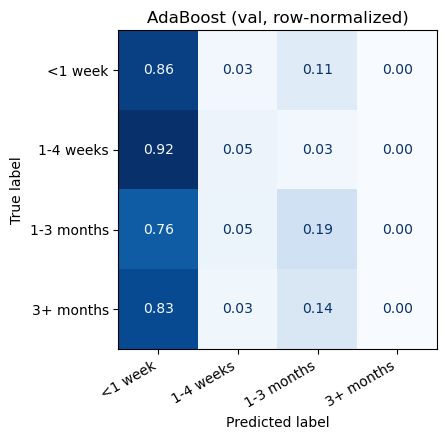

In [3]:
pipe, metrics = utils.evaluate_classifier(model, train, val, name="AdaBoost",
                                           results_dir=RESULTS_DIR)

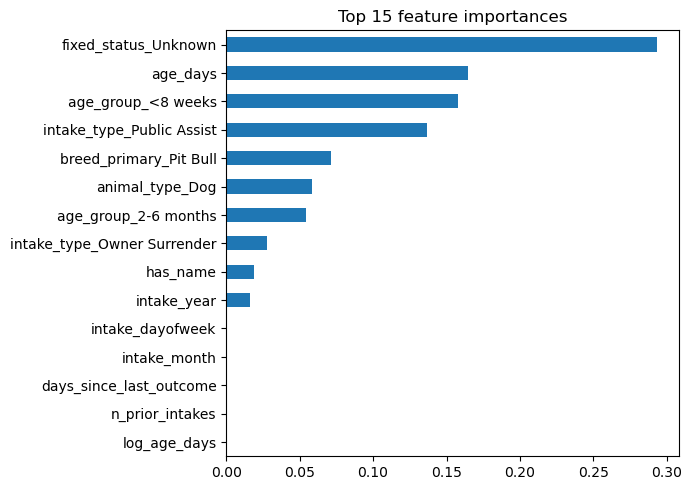

In [4]:
# Impurity-based importances (biased toward high-cardinality / continuous features;
# associations, not causes). Permutation importance is a better check after tuning.
names = pipe.named_steps["pre"].get_feature_names_out()
imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names).nlargest(15)
imp.sort_values().plot(kind="barh", figsize=(7, 5), title="Top 15 feature importances")
plt.tight_layout(); plt.show()

## Hyperparameter tuning (light–medium)

**Randomized search with a time-ordered inner split** (`utils.tune_classifier`):
- Training years are split again, by time and grouped by animal: candidates are fit on intakes before 2021 and scored on 2021 intakes.
- Candidates are ranked by **macro-F1**, so all four bins count equally, not just the dominant `<1 week`.
- The best setting is then refit on the full training set (< 2022) and scored on the **same 2022 val set** as the untuned model.
- Neither val nor test is seen during the search, so the comparison below is fair.

Searched: number of rounds, learning rate, and weak-learner depth. Depth-1 stumps can only learn one-feature effects; depth 2–3 lets the model capture interactions such as species × age.

In [5]:
from scipy.stats import loguniform
from sklearn.tree import DecisionTreeClassifier

base = utils.with_params(model, {'estimator': DecisionTreeClassifier(max_depth=1, random_state=utils.SEED)})
space = {
    'n_estimators': [50, 100, 200, 400],
    'learning_rate': loguniform(0.05, 2),
    'estimator__max_depth': [1, 2, 3],    # stumps vs. small trees
}

best, search_results, tune_info = utils.tune_classifier(
    base, space, train, name="AdaBoost (tuned)", n_iter=15, results_dir=RESULTS_DIR)
search_results.head(10)

time_group_split: dropped 592 rows (0.5%) belonging to animals first seen in an earlier split


AdaBoost (tuned): 15 candidates in 6.1 min | sub-train 115,479, inner-val 10,687 | best inner-val f1_macro 0.336
best params: {'estimator__max_depth': 2, 'learning_rate': 1.6563097558837172, 'n_estimators': 400}


,estimator__max_depth,learning_rate,n_estimators,inner_val_f1_macro,mean_fit_time
0,2,1.656310,400,0.336106,249.254729
1,3,0.268919,200,0.318406,220.381098
2,3,0.258953,200,0.307677,234.790418
3,3,0.944234,200,0.306058,237.120224
4,3,0.093791,200,0.281687,211.937598
5,3,0.887323,50,0.275071,64.264121
6,2,0.109433,400,0.259293,305.617855
7,3,0.272091,50,0.249752,63.188658
8,2,0.104438,200,0.235185,170.331981
9,3,0.053945,100,0.230050,125.759586


== AdaBoost (tuned) ==  macro-F1 0.348  accuracy 0.505
              precision    recall  f1-score   support

     <1 week       0.55      0.75      0.63      4554
   1-4 weeks       0.43      0.42      0.42      3420
  1-3 months       0.50      0.24      0.32      2017
   3+ months       0.33      0.01      0.01       553

    accuracy                           0.50     10544
   macro avg       0.45      0.35      0.35     10544
weighted avg       0.49      0.50      0.47     10544

quadratic weighted kappa: 0.258


train accuracy 0.588  |  fit 211.5s  predict 1.0s


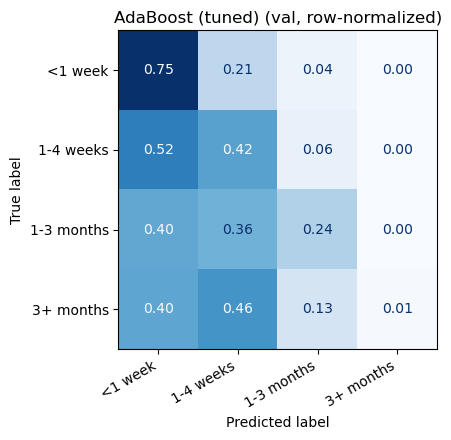

In [6]:
tuned = utils.with_params(base, best)
pipe_tuned, metrics_tuned = utils.evaluate_classifier(
    tuned, train, val, name="AdaBoost (tuned)", results_dir=RESULTS_DIR, extra=tune_info)

### Untuned vs. tuned (val 2022)

In [7]:
pd.DataFrame([metrics, metrics_tuned]).set_index("model")[
    ["accuracy", "macro_f1", "qwk", "train_accuracy"]
    + [f"recall_{c}" for c in utils.LOS_BIN_LABELS]].round(3)

,accuracy,macro_f1,qwk,train_accuracy,recall_<1 week,recall_1-4 weeks,recall_1-3 months,recall_3+ months
model,,,,,,,,
AdaBoost,0.425,0.228,0.048,0.548,0.863,0.052,0.185,0.000
AdaBoost (tuned),0.505,0.348,0.258,0.588,0.749,0.417,0.237,0.007
